# 05 · Models per series against global models

Supports **Section 7.2** of the thesis (local, partially global and fully global models) and research questions
IP2 and IP4. The models were trained by `python src/local_xgb.py` (about three hours on the CPU); this notebook
only reads their outputs and the forecasts of the global models of notebook 04.

**Sample.** 1,000 series, 250 from each Syntetos–Boylan class, drawn at random among the series with at least
365 days since their first sale. Tuning one model per series for all 30,490 series would need about 2.7
million trainings, so the models per series exist only for this sample, and every model is compared on these
1,000 series and on the same days.

**Models compared**, all XGBoost with the Tweedie loss:

| Pooling | Trained on | Models | Tuning |
|---|---|---|---|
| per series | one series | 1,000 per input set (L, L+E, L+E+S) | 30 trials per model |
| sample | the 1,000 series | 1 per input set (L, L+E, L+E+S, L+E+S+ID) | 30 trials per model |
| per store, per demand class | the series of a store or of a class | 10 and 4 (L+E+S+ID) | hyperparameters of the global model |
| all series | all 30,490 series | 1 per input set (L, L+E, L+E+S, L+E+S+ID) | 30 trials per model (notebook 04) |

The models per series and the model of the sample use all 7 horizons of every weekly origin (about 1,900 rows
per series); the model on all series uses 2 of the 7 horizons, drawn at random, to fit in the GPU memory. A
model per series minimises the validation RMSE of its series, the model of the sample the mean RMSSE of the
1,000 series, the model on all series the WRMSSE of the whole hierarchy. The search space of the models per
series has shallower trees (depth 2–8 instead of 4–12) and a smaller `min_child_weight` (0.1–30 instead of
1–300), because they have about a thousand times fewer rows.

**Measure.** RMSSE of each series on the validation window (four weekly origins, d_1914–d_1941), then its
mean over the 1,000 series. WRMSSE is not used here: it needs the whole hierarchy. All models were tuned on
this window, so the numbers are optimistic; the test window is used only in notebook 06.

**Read Section 4 before Sections 2 and 3:** on this window the scores of the models per series are
optimistic by much more than those of the global models.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import m5_data as m5
import metrics as M
from plot_style import SERIES, apply_style, savefig

apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
LOCAL = m5.PROCESSED_DIR / "local_xgb"
RESULTS = ROOT / "results" / "local_xgb"
INPUTS = {"L": "L", "LE": "L+E", "LES": "L+E+S", "LESID": "L+E+S+ID"}
CLASSES = ["smooth", "erratic", "intermittent", "lumpy"]

sample = pd.read_csv(RESULTS / "sample.csv")
rows = sample["row"].to_numpy()
ev = M.Evaluator.for_origin(m5.TRAIN_END, (m5.TRAIN_END + 1, m5.VALID_END), rows=rows)
sample.groupby("sbc_class").agg(series=("id", "size"), median_history_days=("n_active", "median"),
                                median_zero_share=("zero_share", "median")).loc[CLASSES]

,series,median_history_days,median_zero_share
sbc_class,,,
smooth,250,"1,781.000",0.151
erratic,250,"1,898.000",0.178
intermittent,250,"1,709.000",0.703
lumpy,250,"1,891.000",0.520


## 1. Tuning of the models per series (Section 6.6)

In [2]:
per = pd.read_csv(RESULTS / "per_series_best.csv")
pooled = pd.DataFrame(json.loads((RESULTS / "sample_best.json").read_text()))
tuning = per.groupby("inputs", sort=False).agg(models=("id", "size"), rows_median=("rows", "median"),
                                               rounds_median=("rounds", "median"), depth_median=("max_depth", "median"),
                                               learning_rate_median=("learning_rate", "median"),
                                               minutes=("seconds", lambda s: s.sum() / 60))
tuning.index = [f"per series · {INPUTS[i]}" for i in tuning.index]
extra = pd.DataFrame({f"sample · {INPUTS[r.inputs]}": {"models": 1, "rows_median": r.rows, "rounds_median": r.rounds,
                                                      "depth_median": r.max_depth, "learning_rate_median": r.learning_rate,
                                                      "minutes": r.seconds / 60} for r in pooled.itertuples()}).T
tuning = pd.concat([tuning, extra])
tuning.to_csv(RESULTS / "tuning_summary.csv")
print(f"{len(per) * 30 + len(pooled) * 30:,} trainings, {tuning['minutes'].sum():.0f} CPU-core minutes for the models per series and of the sample")
tuning.style.format("{:.0f}").format("{:.3f}", subset=["learning_rate_median"]).format("{:.1f}", subset=["minutes"])

90,120 trainings, 366 CPU-core minutes for the models per series and of the sample


,models,rows_median,rounds_median,depth_median,learning_rate_median,minutes
per series · L,1000,1836,36,6,0.095,75.6
per series · L+E,1000,1836,37,6,0.092,94.8
per series · L+E+S,1000,1836,41,6,0.090,116.1
sample · L,1,1578220,150,12,0.062,11.5
sample · L+E,1,1578220,228,12,0.039,18.6
sample · L+E+S,1,1578220,183,12,0.040,18.8
sample · L+E+S+ID,1,1578220,324,9,0.040,30.6


## 2. Accuracy on the 1,000 series (Section 7.2)

In [3]:
fc = {}
local = np.load(LOCAL / "valid_forecasts.npz")
for i in ["L", "LE", "LES"]:
    fc[("per series", INPUTS[i])] = local[f"per_series_{i}"]
for i in INPUTS:
    fc[("sample (1,000 series)", INPUTS[i])] = local[f"sample_{i}"]
RUNS = m5.PROCESSED_DIR / "global_xgb"


def global_forecast(variant):
    hits = sorted(RUNS.glob(f"*/{variant}/valid_forecast.npy"))
    assert len(hits) == 1, (variant, hits)
    return np.load(hits[0])[rows]


fc[("per store", "L+E+S+ID")] = global_forecast("LESID_tweedie_per_store")
fc[("per demand class", "L+E+S+ID")] = global_forecast("LESID_tweedie_per_class")
for i in INPUTS:
    fc[("all series", INPUTS[i])] = global_forecast(f"{i}_tweedie")
bm = np.load(m5.PROCESSED_DIR / "forecasts" / "benchmarks.npz")
for m, name in {"snaive": "Seasonal naive", "croston": "Croston", "sba": "SBA", "tsb": "TSB", "adida": "ADIDA"}.items():
    fc[("classical", name)] = bm[f"valid_{m}"][rows]

rmsse = pd.DataFrame({k: ev.bottom(f)["rmsse"].to_numpy() for k, f in fc.items()})
rmsse.columns.names = ["pooling", "inputs"]
cls = sample["sbc_class"].to_numpy()
summary = pd.DataFrame({"mean": rmsse.mean(), "median": rmsse.median(),
                        **{c: rmsse[cls == c].mean() for c in CLASSES}})
summary.to_csv(RESULTS / "summary_valid.csv")
out = rmsse.copy()
out.columns = [" · ".join(c) for c in out.columns]
out.insert(0, "id", sample["id"])
out.insert(1, "sbc_class", cls)
out.to_csv(RESULTS / "rmsse_valid.csv", index=False, float_format="%.5f")
summary.style.format("{:.3f}").background_gradient(cmap="Blues_r", subset=["mean"])

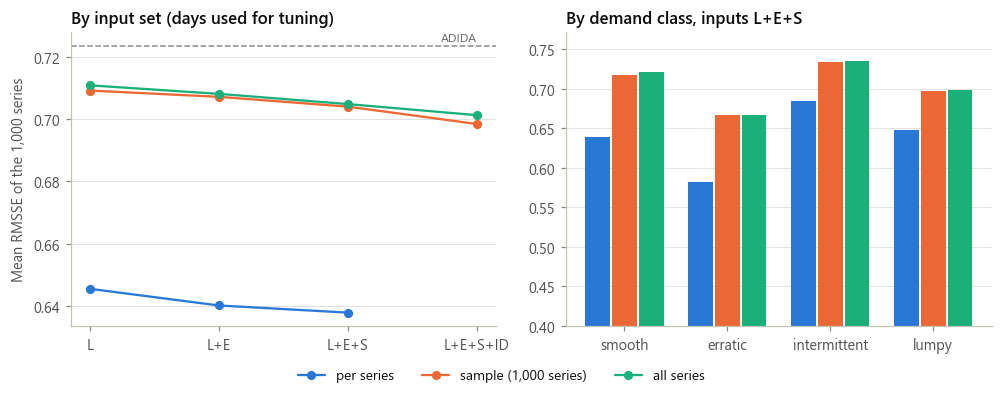

In [4]:
POOL = ["per series", "sample (1,000 series)", "all series"]
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4))
ax = axes[0]
for p, color in zip(POOL, SERIES):
    s = summary.loc[p, "mean"]
    ax.plot(range(len(s)), s.to_numpy(), color=color, marker="o", ms=5, label=p)
ax.axhline(summary.loc[("classical", "ADIDA"), "mean"], color="0.55", lw=1, ls="--")
ax.annotate("ADIDA", (3, summary.loc[("classical", "ADIDA"), "mean"]), xytext=(0, 3), textcoords="offset points",
            ha="right", color="0.4", fontsize=8)
ax.set_xticks(range(4), list(INPUTS.values()))
ax.set_ylabel("Mean RMSSE of the 1,000 series")
ax.set_title("By input set (days used for tuning)")
ax = axes[1]
x = np.arange(len(CLASSES))
for k, (p, color) in enumerate(zip(POOL, SERIES)):
    ax.bar(x + (k - 1) * 0.26, summary.loc[(p, "L+E+S"), CLASSES].to_numpy(), 0.24, color=color, label=p)
ax.set_xticks(x, CLASSES)
ax.set_ylim(0.4, None)
ax.set_title("By demand class, inputs L+E+S")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.03), ncols=3)
savefig(fig, "pooling_sample_valid", subdir="local_xgb")
plt.show()

## 3. Paired comparisons on the same series (IP2, IP4)

For each pair, the difference of RMSSE is taken series by series (second minus first, so a negative mean
favours the second model). The Wilcoxon signed-rank test is given as a description of this window; the
tests of the thesis (Section 7.9) are run on the test window in notebook 06.

In [5]:
def pair(a, b):
    d = rmsse[b] - rmsse[a]
    return {"first": " · ".join(a), "second": " · ".join(b), "mean first": rmsse[a].mean(), "mean second": rmsse[b].mean(),
            "mean difference": d.mean(), "second better (share of series)": (d < 0).mean(), "ties": (d == 0).mean(),
            "Wilcoxon p": wilcoxon(d).pvalue if (d != 0).any() else np.nan}


PAIRS = ([(("per series", i), ("sample (1,000 series)", i)) for i in ["L", "L+E", "L+E+S"]] +
         [(("per series", i), ("all series", i)) for i in ["L", "L+E", "L+E+S"]] +
         [(("sample (1,000 series)", i), ("all series", i)) for i in INPUTS.values()] +
         [(("per series", "L"), ("per series", "L+E")), (("per series", "L+E"), ("per series", "L+E+S")),
          (("per series", "L+E+S"), ("all series", "L+E+S+ID")), (("classical", "ADIDA"), ("per series", "L+E+S")),
          (("classical", "ADIDA"), ("all series", "L+E+S+ID"))])
pairs = pd.DataFrame([pair(a, b) for a, b in PAIRS])
pairs.to_csv(RESULTS / "pairs_valid.csv", index=False)
pairs.style.format("{:.3f}", subset=["mean first", "mean second", "mean difference"]).format(
    "{:.0%}", subset=["second better (share of series)", "ties"]).format("{:.3f}", subset=["Wilcoxon p"])

,first,second,mean first,mean second,mean difference,second better (share of series),ties,Wilcoxon p
0,per series · L,"sample (1,000 series) · L",0.645,0.709,0.064,6%,0%,0.000
1,per series · L+E,"sample (1,000 series) · L+E",0.640,0.707,0.067,5%,0%,0.000
2,per series · L+E+S,"sample (1,000 series) · L+E+S",0.638,0.704,0.066,3%,0%,0.000
3,per series · L,all series · L,0.645,0.711,0.065,5%,0%,0.000
4,per series · L+E,all series · L+E,0.640,0.708,0.068,5%,0%,0.000
5,per series · L+E+S,all series · L+E+S,0.638,0.705,0.067,4%,0%,0.000
6,"sample (1,000 series) · L",all series · L,0.709,0.711,0.002,47%,0%,0.029
7,"sample (1,000 series) · L+E",all series · L+E,0.707,0.708,0.001,50%,0%,0.530
8,"sample (1,000 series) · L+E+S",all series · L+E+S,0.704,0.705,0.001,49%,0%,0.385
9,"sample (1,000 series) · L+E+S+ID",all series · L+E+S+ID,0.698,0.701,0.003,46%,0%,0.000


The gap between the models per series and the model on all series, by input set (the question of IP2: do
the inputs known in advance close the gap?):

In [6]:
gap = pd.DataFrame({i: {"per series": summary.loc[("per series", i), "mean"],
                        "all series": summary.loc[("all series", i), "mean"]} for i in ["L", "L+E", "L+E+S"]}).T
gap["gap (per series − all series)"] = gap["per series"] - gap["all series"]
by_class = pd.DataFrame({i: (rmsse[("per series", i)] - rmsse[("all series", i)]).groupby(cls).mean()
                         for i in ["L", "L+E", "L+E+S"]}).T[CLASSES]
gap = pd.concat([gap, by_class.add_prefix("gap · ")], axis=1)
gap.to_csv(RESULTS / "gap_by_inputs_valid.csv")
gap

,per series,all series,gap (per series − all series),gap · smooth,gap · erratic,gap · intermittent,gap · lumpy
L,0.645,0.711,-0.065,-0.081,-0.086,-0.049,-0.045
L+E,0.640,0.708,-0.068,-0.084,-0.085,-0.051,-0.051
L+E+S,0.638,0.705,-0.067,-0.082,-0.085,-0.050,-0.050


## 4. Selection bias of the models per series

A model per series chooses its hyperparameters and its number of rounds (30 trials, each with early
stopping) on the 28 validation days of its own series, and Sections 2 and 3 score it on the same 28 days.
A model shared by many series cannot adapt to one series in this way, so the comparison above favours the
models per series. The check below does not touch the test window: the models per series are tuned again,
choosing on the **first 14 days** of the validation window only, and all models are scored on the
**last 14 days**. The global models are the same as above (their choice used all 28 days, but one setting
for 30,490 series).

In [7]:
half = np.load(LOCAL / "valid_forecasts_first_half.npz")
actual, scale = ev.actual[12], ev.scale[12]


def rmsse_days(f, days):
    return np.sqrt(np.mean((f[:, days] - actual[:, days]) ** 2, axis=1) / scale)


FIRST, LAST = slice(0, 14), slice(14, 28)
check = {}
for i in ["L", "LE", "LES"]:
    own, shared = half[f"per_series_{i}"], fc[("all series", INPUTS[i])]
    d = rmsse_days(shared, LAST) - rmsse_days(own, LAST)
    check[INPUTS[i]] = {
        "per series, days 1–14 (chosen on them)": rmsse_days(own, FIRST).mean(),
        "all series, days 1–14": rmsse_days(shared, FIRST).mean(),
        "per series, days 15–28 (not seen)": rmsse_days(own, LAST).mean(),
        "per series chosen on all 28 days, days 15–28": rmsse_days(fc[("per series", INPUTS[i])], LAST).mean(),
        "sample (1,000 series), days 15–28": rmsse_days(fc[("sample (1,000 series)", INPUTS[i])], LAST).mean(),
        "all series, days 15–28": rmsse_days(shared, LAST).mean(),
        "all series better on days 15–28 (share of series)": (d < 0).mean(),
        "Wilcoxon p, days 15–28": wilcoxon(d).pvalue}
check = pd.DataFrame(check)
check.to_csv(RESULTS / "selection_bias_valid.csv")
check

,L,L+E,L+E+S
"per series, days 1–14 (chosen on them)",0.587,0.577,0.577
"all series, days 1–14",0.685,0.682,0.680
"per series, days 15–28 (not seen)",0.720,0.717,0.712
"per series chosen on all 28 days, days 15–28",0.639,0.637,0.632
"sample (1,000 series), days 15–28",0.700,0.698,0.692
"all series, days 15–28",0.699,0.697,0.692
all series better on days 15–28 (share of series),0.569,0.576,0.596
"Wilcoxon p, days 15–28",0.000,0.000,0.000


## Key findings

All numbers are from the validation window, on which every model was tuned.

1. **The validation scores of the models per series cannot be compared with those of the global models.**
   Scored on the 28 days on which they were chosen, the models per series have a mean RMSSE of 0.64–0.65
   against 0.70–0.71 for the model on all series, and are better on about 19 series in 20. On days they
   have not seen the order turns: 0.71–0.72 for the models per series against 0.69–0.70 for the model on
   all series, which is better on 57–60% of the series (Wilcoxon p < 10⁻⁶ for every input set). The
   advantage in Sections 2 and 3 is selection bias, not accuracy.
2. **Pooling (IP4).** On unseen days the model on all series is more accurate than the models per series
   by about 0.02 and as accurate as the model trained on the 1,000 series alone (0.69–0.70). Beyond 1,000
   series, more series in the training set change little on single series: the model of the sample, the
   models per store and per demand class and the model on all series are within 0.005 of each other.
3. **Inputs (IP2).** The inputs known in advance and the statistics change the mean RMSSE of the models per
   series by less than 0.01, as for the global model. The gap between local and global models does not
   depend on the input set in this window.
4. **Against the classical methods.** ADIDA has 0.724 on the 1,000 series, the model on all series with
   L+E+S+ID 0.701 (better on 68% of the series).
5. **Limits.** One window; choosing on 14 days is noisier than on 28, so the check is somewhat unfavourable
   to the models per series. The comparison that counts is on the test window (notebook 06), where no model
   has seen the days it is scored on.